# Stage 4: Ordinal Regression for Diabetic Retinopathy Grading
### Does treating the DR grade as an ordered number (instead of five unrelated classes) improve grading on APTOS 2019?

**Hypothesis (M3, written before this notebook was run):** [`stage4_hypothesis.md`](stage4_hypothesis.md). In one sentence: replacing the five-class cross-entropy output with **ordinal regression** (one output, mean-squared error against the grade, decoded with cut-offs tuned on the validation set) raises QWK and reduces large grading errors, because the loss then matches the ordered grades and the quadratic penalty inside QWK.

**Baseline:** the best Stage 3 setting `2_aug_lr1e-4` (paper pipeline, 300 px, 60 epochs, batch 16, augmentation, lr 1e-4): test QWK 0.908 single / 0.898 snapshot vote.

**The one change, and the four arms that isolate it**

| Arm | Trained with | Output -> grade | Question |
|---|---|---|---|
| **A** | cross-entropy (baseline) | arg-max (ensemble: majority vote, as in the paper) | reference |
| **B** | cross-entropy (same model as A) | expected grade + validation-tuned cut-offs | is it only the decision rule? |
| **C** | MSE regression | round to the nearest grade | is it only the loss? |
| **D** | MSE regression (same model as C) | validation-tuned cut-offs | **the hypothesis** |

Two models are trained per seed (cross-entropy, regression). B and D cost no extra training. Three training seeds on the same split measure training randomness, and one extra pair on **de-duplicated** data checks that the result does not come from duplicate leakage.

**How to run (Colab)**

1. **Runtime -> Change runtime type -> T4 GPU**, then **Runtime -> Run all**, and allow Google Drive access.
2. The image cache from the Stage 3 notebook (`MyDrive/dr-grading/aptos512.zip`) is reused, so there is no re-download. Without it, the first run downloads APTOS once (~15 min).
3. 8 runs x ~30 min = **about 4 hours** on a T4. Everything is saved to `MyDrive/dr-grading/stage4/` after every epoch. **If Colab disconnects, just Run all again**: finished runs are loaded, the unfinished one resumes after its last completed epoch.
4. Set `QUICK_TEST = True` first for a ~5-minute check that everything works (it writes to a separate folder).

*This is a reproduction study, not a clinical tool.*

## 1. Setup and settings

Every hyper-parameter lives in one `Config`. The defaults are the Stage 3 baseline; an experiment changes only `loss` (`"ce"` or `"mse"`), `seed` and `dedupe`.

In [1]:
import hashlib
import io
import json
import math
import os
import random
import subprocess
import time
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict, dataclass, fields, replace
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support, roc_auc_score
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

try:
    import timm
except ImportError:                      # not preinstalled on this machine
    !pip install -q timm
    import timm

CLASS_NAMES = ["No DR", "Mild", "Moderate", "Severe", "PDR"]
NUM_CLASSES = len(CLASS_NAMES)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Results and the data cache live on Google Drive, so a Colab disconnect loses nothing.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = Path("/content/drive/MyDrive/dr-grading")      # shared with the Stage 3 notebook (data cache)
    LOCAL_DIR = Path("/content")                               # fast local disk for the unpacked images
except ImportError:                                            # running outside Colab
    WORK_DIR = Path(os.environ.get("DR_WORK_DIR", "dr-grading")).resolve()
    LOCAL_DIR = WORK_DIR
WORK_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "no GPU found (very slow!)")

Mounted at /content/drive
device: cuda | Tesla T4


In [2]:
QUICK_TEST = False        # True = tiny run (few epochs, few batches, separate output folder) to check the pipeline
RUN_DEDUPE_CHECK = True   # the extra pair of runs on de-duplicated data (prediction P8)
CHECKPOINT_EVERY = 1      # save a resumable checkpoint every N epochs
SPLIT_SEED = 42           # the train/val/test split is the same for every run (same as Stage 3)


@dataclass
class Config:
    # The Stage 3 baseline `2_aug_lr1e-4`: paper settings plus augmentation and lr 1e-4.
    image_size: int = 300
    epochs: int = 60
    batch_size: int = 16
    lr: float = 1e-4
    weight_decay: float = 1e-4
    grad_clip: float = 0.1
    n_snapshots: int = 10
    seed: int = 42                # training seed (weights init, batch order, augmentation); the split stays fixed
    backbone: str = "efficientnet_b3"
    pretrained: bool = True
    use_amp: bool = True
    augment: bool = True
    loss: str = "ce"              # "ce" = 5-class cross-entropy (baseline); "mse" = ordinal regression (Stage 4)
    dedupe: bool = False          # True = drop conflicting duplicates and keep one copy of each identical image
    max_train_batches: int = 0    # 0 = all batches; >0 only for the quick test


BASE_CFG = Config()
SEEDS = [42, 43, 44]
STAGE4_DIR = WORK_DIR / "stage4"
if QUICK_TEST:
    BASE_CFG = replace(BASE_CFG, epochs=4, n_snapshots=2, max_train_batches=5, image_size=224)
    SEEDS = [42, 43]
    STAGE4_DIR = WORK_DIR / "stage4_quick_test"            # never mixed with the real runs
if device.type != "cuda":
    BASE_CFG = replace(BASE_CFG, use_amp=False)             # mixed precision is a GPU feature
RUNS_DIR, FIG_DIR = STAGE4_DIR / "runs", STAGE4_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Interleaved so that the first finished pair (seed 42) can already be compared.
EXPERIMENTS = {}
for seed in SEEDS:
    for loss in ("ce", "mse"):
        EXPERIMENTS[f"{loss}_s{seed}"] = replace(BASE_CFG, loss=loss, seed=seed)
if RUN_DEDUPE_CHECK:
    for loss in ("ce", "mse"):
        EXPERIMENTS[f"{loss}_s{SEEDS[0]}_dedupe"] = replace(BASE_CFG, loss=loss, seed=SEEDS[0], dedupe=True)

print(json.dumps(asdict(BASE_CFG), indent=2))
print("experiments:", ", ".join(EXPERIMENTS))

{
  "image_size": 300,
  "epochs": 60,
  "batch_size": 16,
  "lr": 0.0001,
  "weight_decay": 0.0001,
  "grad_clip": 0.1,
  "n_snapshots": 10,
  "seed": 42,
  "backbone": "efficientnet_b3",
  "pretrained": true,
  "use_amp": true,
  "augment": true,
  "loss": "ce",
  "dedupe": false,
  "max_train_batches": 0
}
experiments: ce_s42, mse_s42, ce_s43, mse_s43, ce_s44, mse_s44, ce_s42_dedupe, mse_s42_dedupe


## 2. Data

APTOS 2019: 3,662 labelled fundus photographs, five grades. Same source and cache as Stage 3: the full-resolution Hugging Face mirror [`sngsfydy/aptos`](https://huggingface.co/datasets/sngsfydy/aptos), shrunk to 512 px on the long side, with a zipped copy on Drive. Because the image order comes from the same `labels.csv`, the split below is **identical to Stage 3**.

In [3]:
HF_REPO = "sngsfydy/aptos"
IMG_DIR = LOCAL_DIR / "aptos512"
DRIVE_CACHE = WORK_DIR / "aptos512.zip"
MAX_SIDE = 512


def list_shards():
    with urllib.request.urlopen(f"https://huggingface.co/api/datasets/{HF_REPO}/tree/main/data") as r:
        return sorted(f["path"] for f in json.load(r) if f["path"].endswith(".parquet"))


def convert_shard(parquet_path, out_dir):
    # Save every image in one parquet shard as a <hash>.jpg (<= 512 px). Returns [(file name, grade), ...].
    rows = []
    pf = pq.ParquetFile(parquet_path)
    for group in range(pf.num_row_groups):
        table = pf.read_row_group(group).to_pydict()
        for img, label in zip(table["image"], table["label"]):
            raw = img["bytes"]
            name = hashlib.sha1(raw).hexdigest()[:16] + ".jpg"     # identical photos get identical names
            im = Image.open(io.BytesIO(raw)).convert("RGB")
            scale = MAX_SIDE / max(im.size)
            im.resize((round(im.width * scale), round(im.height * scale)), Image.LANCZOS).save(out_dir / name, quality=95)
            rows.append((name, int(label)))
    return rows


def download_aptos(out_dir):
    out_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    for shard in list_shards():
        local = LOCAL_DIR / Path(shard).name
        print("downloading", local.name, flush=True)
        subprocess.run(["curl", "-sSL", "--retry", "5", "-o", str(local),
                        f"https://huggingface.co/datasets/{HF_REPO}/resolve/main/{shard}"], check=True)
        rows += convert_shard(local, out_dir)
        local.unlink()                                             # free the disk before the next shard
        print(f"  {len(rows)} images so far", flush=True)
    pd.DataFrame(rows, columns=["id_code", "label"]).to_csv(out_dir / "labels.csv", index=False)


if not (IMG_DIR / "labels.csv").exists():
    if DRIVE_CACHE.exists():                                       # Stage 3 (or an earlier session) did the download
        print("restoring cached images from Drive ...")
        subprocess.run(["unzip", "-q", "-o", str(DRIVE_CACHE), "-d", str(IMG_DIR)], check=True)
    else:
        download_aptos(IMG_DIR)
        print("saving a cache to Drive for next time ...")
        subprocess.run(["zip", "-q", "-r", "-j", str(DRIVE_CACHE), str(IMG_DIR)], check=True)

df = pd.read_csv(IMG_DIR / "labels.csv")
df["path"] = df["id_code"].map(lambda name: IMG_DIR / name)
labels = df["label"].to_numpy()
print(f"{len(df)} images, {df['id_code'].nunique()} distinct files")

restoring cached images from Drive ...
3662 images, 3534 distinct files


### Duplicates and the two splits

APTOS contains byte-identical images, some with **conflicting grades**. The main experiments use the Stage 3 split (all images, stratified 70/15/15, seed 42). The de-duplication check (prediction P8) uses a second split built after **removing every image whose copies disagree** and **keeping one copy of each remaining identical group**, so no test image has a twin in training.

In [4]:
def file_hash(path):
    return hashlib.md5(path.read_bytes()).hexdigest()


with ThreadPoolExecutor(os.cpu_count()) as pool:
    df["hash"] = list(tqdm(pool.map(file_hash, df["path"]), total=len(df), desc="hashing"))

groups = df.groupby("hash")["label"].agg(["size", "nunique"])
conflict_hashes = set(groups.index[groups["nunique"] > 1])
df["conflicting_duplicate"] = df["hash"].isin(conflict_hashes)
print(f"{int((groups['size'] > 1).sum())} groups of identical images, {len(conflict_hashes)} of them with conflicting grades")


def make_split(positions, seed=SPLIT_SEED, val_frac=0.15, test_frac=0.15):
    # Stratified train/val/test row positions (into df). With all positions this is exactly the Stage 3 split.
    train_val, test = train_test_split(positions, test_size=test_frac, stratify=labels[positions], random_state=seed)
    train, val = train_test_split(train_val, test_size=val_frac / (1 - test_frac),
                                  stratify=labels[train_val], random_state=seed)
    return {"train": np.sort(train), "val": np.sort(val), "test": np.sort(test)}


keep = ~df["conflicting_duplicate"] & ~df.duplicated("hash")      # de-duplicated data set
SPLITS = {False: make_split(np.arange(len(df))), True: make_split(np.flatnonzero(keep.to_numpy()))}

for dedupe, split in SPLITS.items():
    train_hashes = set(df["hash"].to_numpy()[split["train"]])
    leaked = sum(h in train_hashes for h in df["hash"].to_numpy()[split["test"]])
    print(f"\n{'de-duplicated' if dedupe else 'all images (Stage 3 split)'}: {sum(map(len, split.values()))} images, "
          f"{leaked} test images with a twin in training")
    print(pd.DataFrame({name: np.bincount(labels[idx], minlength=NUM_CLASSES) for name, idx in split.items()},
                       index=CLASS_NAMES).T.to_string())

hashing:   0%|          | 0/3662 [00:00<?, ?it/s]

123 groups of identical images, 30 of them with conflicting grades

all images (Stage 3 split): 3662 images, 29 test images with a twin in training
       No DR  Mild  Moderate  Severe  PDR
train   1263   258       699     135  207
val      271    56       150      29   44
test     271    56       150      29   44

de-duplicated: 3504 images, 0 test images with a twin in training
       No DR  Mild  Moderate  Severe  PDR
train   1257   236       646     124  189
val      269    51       138      27   41
test     270    51       138      26   41


## 3. Pre-processing (unchanged from Stage 3)

CLAHE on the LAB lightness channel (clip 2.0, 8x8 tiles), 5x5 Gaussian blur, square resize to 300 px. Computed once for all images and kept in memory (~1 GB).

In [5]:
def preprocess(path, size):
    # Load -> shrink to <= 512 px -> CLAHE + blur -> square resize. Returns RGB uint8 (size, size, 3).
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    h, w = bgr.shape[:2]
    if max(h, w) > 512:
        scale = 512 / max(h, w)
        bgr = cv2.resize(bgr, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    bgr = cv2.GaussianBlur(cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), (5, 5), 0)
    bgr = cv2.resize(bgr, (size, size), interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


paths = df["path"].tolist()
images = np.empty((len(paths), BASE_CFG.image_size, BASE_CFG.image_size, 3), dtype=np.uint8)


def fill(i):
    images[i] = preprocess(paths[i], BASE_CFG.image_size)


t0 = time.time()
with ThreadPoolExecutor(os.cpu_count()) as pool:            # OpenCV releases the GIL, so threads are enough
    list(tqdm(pool.map(fill, range(len(paths))), total=len(paths), desc="pre-processing"))
print(f"{images.shape}, {images.nbytes / 1e9:.2f} GB, {time.time() - t0:.0f}s")

pre-processing:   0%|          | 0/3662 [00:00<?, ?it/s]

(3662, 300, 300, 3), 0.99 GB, 33s


## 4. Model: the only architectural difference is the last layer

EfficientNet-B3 (ImageNet weights) with the paper's head. The baseline ends in **5 outputs** (one score per grade, softmax + cross-entropy). The ordinal model ends in **1 output**: a number on the 0-4 scale, trained with mean-squared error against the true grade. Everything before the last layer is identical.

```
1536 -> Linear 512 -> Dropout 0.5 -> ReLU -> Linear 512 -> Dropout 0.25 -> ReLU -> Linear 5   (baseline, "ce")
                                                                               -> Linear 1   (ordinal,  "mse")
```

**Why MSE:** an error of *d* grades costs *d*², which is exactly the quadratic weight QWK uses. Cross-entropy charges every wrong grade the same.

In [6]:
def n_outputs(cfg):
    return 1 if cfg.loss == "mse" else NUM_CLASSES


class DRNet(nn.Module):
    def __init__(self, backbone="efficientnet_b3", pretrained=True, outputs=NUM_CLASSES):
        super().__init__()
        self.backbone = timm.create_model(backbone, pretrained=pretrained, num_classes=0, global_pool="avg")
        self.head = nn.Sequential(
            nn.Linear(self.backbone.num_features, 512), nn.Dropout(0.5), nn.ReLU(inplace=True),
            nn.Linear(512, 512), nn.Dropout(0.25), nn.ReLU(inplace=True),
            nn.Linear(512, outputs),
        )

    def forward(self, x):
        return self.head(self.backbone(x))


_mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
_std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)
_black = -_mean / _std     # what a black pixel looks like after normalisation


def to_model_input(batch_uint8):
    # numpy (B, H, W, 3) uint8 -> normalised float tensor (B, 3, H, W) on the GPU.
    x = torch.from_numpy(batch_uint8).to(device).permute(0, 3, 1, 2).float() / 255.0
    return ((x - _mean) / _std).contiguous(memory_format=torch.channels_last)


def augment_batch(x):
    # Random horizontal flip + random rotation (0-360 degrees), as in Stage 3. Empty corners stay black.
    n = x.shape[0]
    x = x - _black
    flip = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip.view(-1, 1, 1, 1), x.flip(-1), x)
    angle = torch.rand(n, device=x.device) * 2 * math.pi
    cos, sin, zero = angle.cos(), angle.sin(), torch.zeros_like(angle)
    theta = torch.stack([torch.stack([cos, -sin, zero], 1), torch.stack([sin, cos, zero], 1)], 1)    # (n, 2, 3)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    return (x + _black).contiguous(memory_format=torch.channels_last)

## 5. From model output to a grade, and the metrics

A model's raw output for an image is either 5 probabilities (`ce`) or one number (`mse`). Both can be turned into a **continuous severity score**: the expected grade Σ k·p(k) for `ce`, the number itself for `mse`. A score becomes a grade through four **cut-offs**: rounding uses 0.5 / 1.5 / 2.5 / 3.5; the tuned rule searches each cut-off on a 0.01 grid to maximise **validation** QWK (coordinate search, three passes). The test set never influences a cut-off.

**Metrics** (all on the test set): QWK, accuracy, macro-F1, recall per grade, errors of two or more grades, the confusion matrix, and the screening view **referable DR = grade >= 2**: sensitivity, specificity and AUC. For a fair AUC across both models, the score for "grade >= k" is Σ_{j>=k} p(j) for `ce` and the regression output for `mse`; *ordinal AUC* is the mean over k = 1..4.

In [7]:
ROUNDING = np.array([0.5, 1.5, 2.5, 3.5])


def qwk(y, pred, k=NUM_CLASSES):
    # Quadratic weighted kappa from the confusion matrix (same value as sklearn's cohen_kappa_score, much faster).
    cm = np.bincount(y * k + pred, minlength=k * k).reshape(k, k).astype(float)
    weights = np.subtract.outer(np.arange(k), np.arange(k)) ** 2 / (k - 1) ** 2
    expected = np.outer(cm.sum(1), cm.sum(0)) / cm.sum()
    denom = (weights * expected).sum()
    return float(1 - (weights * cm).sum() / denom) if denom > 0 else 0.0


def severity_score(out):
    # (..., 5) probabilities -> expected grade; (..., 1) regression output -> that number.
    return out @ np.arange(NUM_CLASSES) if out.shape[-1] == NUM_CLASSES else out[..., 0]


def at_least_score(out, k):
    # Score for "grade >= k": P(grade >= k) for ce, the regression output for mse (any monotone score works for AUC).
    return out[..., k:].sum(-1) if out.shape[-1] == NUM_CLASSES else out[..., 0]


def apply_cutoffs(score, cutoffs):
    return np.digitize(score, cutoffs).astype(int)


def fit_cutoffs(score, y, step=0.01, passes=3):
    # Coordinate search: move one cut-off at a time to the grid value with the best QWK, keeping them ordered.
    cutoffs = ROUNDING.copy()
    best = qwk(y, apply_cutoffs(score, cutoffs))
    for _ in range(passes):
        for i in range(len(cutoffs)):
            lo = cutoffs[i - 1] + step if i > 0 else -0.5
            hi = cutoffs[i + 1] - step if i < len(cutoffs) - 1 else NUM_CLASSES - 0.5
            for value in np.arange(lo, hi + 1e-9, step):
                trial = cutoffs.copy()
                trial[i] = value
                score_trial = qwk(y, apply_cutoffs(score, trial))
                if score_trial > best:                       # strictly better: ties keep the current cut-off
                    best, cutoffs = score_trial, trial
    return cutoffs


def majority_vote(snapshot_probs):
    # snapshot_probs: (n_snapshots, n_images, 5) -> one predicted grade per image (paper's ensemble rule).
    votes = snapshot_probs.argmax(-1)
    tally = np.stack([(votes == c).sum(0) for c in range(NUM_CLASSES)], 1).astype(float)
    tally += 1e-3 * snapshot_probs.mean(0)                   # tie-break
    return tally.argmax(1)


def safe_auc(y_binary, score):
    return float(roc_auc_score(y_binary, score)) if 0 < y_binary.sum() < len(y_binary) else float("nan")


def compute_metrics(y, pred, out):
    _, rec, _, _ = precision_recall_fscore_support(y, pred, labels=list(range(NUM_CLASSES)), zero_division=0)
    ref_true, ref_pred = y >= 2, pred >= 2
    return {
        "qwk": qwk(y, pred),
        "accuracy": float(accuracy_score(y, pred)),
        "macro_f1": float(f1_score(y, pred, average="macro", labels=list(range(NUM_CLASSES)), zero_division=0)),
        **{f"recall_{name}": float(rec[c]) for c, name in enumerate(CLASS_NAMES)},
        "off_by_2_or_more": int(np.sum(np.abs(y - pred) >= 2)),
        "ref_sensitivity": float((ref_pred & ref_true).sum() / max(ref_true.sum(), 1)),
        "ref_specificity": float((~ref_pred & ~ref_true).sum() / max((~ref_true).sum(), 1)),
        "ref_auc": safe_auc(ref_true, at_least_score(out, 2)),
        "ordinal_auc": float(np.nanmean([safe_auc(y >= k, at_least_score(out, k)) for k in range(1, NUM_CLASSES)])),
        "confusion_matrix": confusion_matrix(y, pred, labels=list(range(NUM_CLASSES))).tolist(),
    }

In [8]:
ARMS = {"ce": ("A", "B"), "mse": ("C", "D")}     # (default rule, tuned-cut-off rule) for each trained model


def decide(run, mode):
    # Grades for the test set from one finished run, for both of its arms.
    # mode "single" = the best-validation epoch; "ensemble" = the 10 snapshots.
    if mode == "single":
        val_out, test_out = run["best_val"], run["best_test"]
    else:
        val_out, test_out = run["snap_val"].mean(0), run["snap_test"].mean(0)
    default_arm, tuned_arm = ARMS[run["config"].loss]
    if run["config"].loss == "ce":                  # A: arg-max / the paper's majority vote
        default = test_out.argmax(1) if mode == "single" else majority_vote(run["snap_test"])
    else:                                           # C: round the regression output
        default = apply_cutoffs(severity_score(test_out), ROUNDING)
    cutoffs = fit_cutoffs(severity_score(val_out), run["y_val"])          # B / D: cut-offs from validation only
    tuned = apply_cutoffs(severity_score(test_out), cutoffs)
    return {default_arm: (default, test_out, None), tuned_arm: (tuned, test_out, cutoffs)}

## 6. Training (same loop as Stage 3)

Per epoch: one pass over the training set, then predict the validation set. The **best epoch is chosen on validation QWK with the model's default rule** (arg-max for `ce`, rounding for `mse`), fixed before running. We keep validation *and* test outputs for the best epoch and for the 10 snapshot epochs, so that cut-offs can later be tuned on validation without retraining.

**Safety net:** after every epoch the log goes to `runs/<name>/log.csv` and a resumable checkpoint `last.pt` is written atomically. Re-running the notebook skips finished runs and resumes an interrupted one.

In [9]:
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def make_criterion(cfg):
    if cfg.loss == "ce":
        return nn.CrossEntropyLoss()
    if cfg.loss == "mse":                           # ordinal regression: squared distance to the true grade
        return lambda out, y: F.mse_loss(out[:, 0], y.float())
    raise ValueError(f"unknown loss {cfg.loss!r}")


def default_grades(out):
    # The rule used to pick the best epoch: arg-max for ce, rounding for mse.
    return out.argmax(1) if out.shape[1] == NUM_CLASSES else apply_cutoffs(out[:, 0], ROUNDING)


@torch.no_grad()
def predict(model, indices, cfg, batch_size=32):
    # Softmax probabilities (n, 5) for ce, the raw regression output (n, 1) for mse.
    model.eval()
    out = []
    for start in range(0, len(indices), batch_size):
        x = to_model_input(images[indices[start:start + batch_size]])
        with torch.autocast(device.type, dtype=torch.float16, enabled=cfg.use_amp):
            logits = model(x).float()
        out.append((torch.softmax(logits, dim=1) if cfg.loss == "ce" else logits).cpu())
    return torch.cat(out).numpy()


def train_one_epoch(model, optimizer, scaler, criterion, cfg, split, rng):
    model.train()
    order = rng.permutation(split["train"])
    n_batches = len(order) // cfg.batch_size                                   # drop the last partial batch
    if cfg.max_train_batches:
        n_batches = min(n_batches, cfg.max_train_batches)
    total_loss, seen = 0.0, 0
    progress = tqdm(range(n_batches), desc="  training", leave=False)
    for b in progress:
        idx = np.sort(order[b * cfg.batch_size:(b + 1) * cfg.batch_size])      # sorted = faster memory reads
        x = to_model_input(images[idx])
        if cfg.augment:
            x = augment_batch(x)
        y = torch.from_numpy(labels[idx]).to(device)

        with torch.autocast(device.type, dtype=torch.float16, enabled=cfg.use_amp):
            out = model(x)
        loss = criterion(out.float(), y)

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)                                             # so clipping sees real gradient sizes
        nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * len(y)
        seen += len(y)
        progress.set_postfix(loss=f"{total_loss / seen:.3f}")
    return total_loss / seen

In [10]:
def save_atomically(path, obj):
    # Write to a temp file, then rename: a crash mid-save can never leave a broken file behind.
    tmp = path.with_suffix(".tmp")
    try:
        torch.save(obj, tmp)
        tmp.replace(path)
    except (RuntimeError, OSError) as err:
        tmp.unlink(missing_ok=True)
        print(f"  warning: could not save {path.name} ({err})")


def load_run(run_dir, cfg):
    saved = np.load(run_dir / "outputs.npz")
    return {"config": cfg, "log": pd.read_csv(run_dir / "log.csv"), **{k: saved[k] for k in saved.files}}


def run_experiment(name, cfg):
    # Train one configuration and save its validation/test outputs. Resumes if interrupted.
    run_dir = RUNS_DIR / name
    run_dir.mkdir(parents=True, exist_ok=True)
    config_file, done_file = run_dir / "config.json", run_dir / "results.json"
    ckpt_path, best_path = run_dir / "last.pt", run_dir / "best_val_weights.pt"

    saved_cfg = json.loads(config_file.read_text()) if config_file.exists() else None
    if saved_cfg is not None:
        saved_cfg = {**{f.name: f.default for f in fields(Config)}, **saved_cfg}
    if saved_cfg != asdict(cfg):              # a new experiment, or its settings changed: ignore any old files
        ckpt_path.unlink(missing_ok=True)
        done_file.unlink(missing_ok=True)
        config_file.write_text(json.dumps(asdict(cfg), indent=2))
    if done_file.exists():                    # finished in an earlier session
        print(f"=== {name} === already finished, loading saved outputs")
        return load_run(run_dir, cfg)

    split = SPLITS[cfg.dedupe]
    print(f"\n=== {name} ===  loss={cfg.loss}  seed={cfg.seed}  dedupe={cfg.dedupe}  lr={cfg.lr}  epochs={cfg.epochs}")
    seed_everything(cfg.seed)
    model = DRNet(cfg.backbone, cfg.pretrained, n_outputs(cfg)).to(device).to(memory_format=torch.channels_last)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scaler = torch.amp.GradScaler("cuda", enabled=cfg.use_amp)
    criterion = make_criterion(cfg)
    rng = np.random.default_rng(cfg.seed)

    snapshot_epochs = {round(cfg.epochs * k / cfg.n_snapshots) for k in range(1, cfg.n_snapshots + 1)}
    progress = {"log": [], "snap_val": [], "snap_test": [], "best_val_qwk": -2.0, "best_epoch": 0,
                "best_val": None, "best_test": None}
    first_epoch = 1

    if ckpt_path.exists():                                                     # continue an interrupted run
        try:
            ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        except Exception as err:
            ckpt = None
            print(f"  could not read {ckpt_path.name} ({err}); starting from scratch")
        if ckpt is not None:
            model.load_state_dict(ckpt["model"])
            optimizer.load_state_dict(ckpt["optimizer"])
            scaler.load_state_dict(ckpt["scaler"])
            rng.bit_generator.state = ckpt["rng_numpy"]
            torch.set_rng_state(ckpt["rng_torch"])
            if ckpt["rng_cuda"] is not None:
                torch.cuda.set_rng_state_all(ckpt["rng_cuda"])
            progress, first_epoch = ckpt["progress"], ckpt["epoch"] + 1
            print(f"  RESUMED after epoch {ckpt['epoch']} (best so far: val QWK {progress['best_val_qwk']:.3f})")

    y_val = labels[split["val"]]
    started, epochs_done_now = time.time(), 0
    for epoch in range(first_epoch, cfg.epochs + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, optimizer, scaler, criterion, cfg, split, rng)

        val_out = predict(model, split["val"], cfg)
        val_pred = default_grades(val_out)
        val_qwk, val_acc = qwk(y_val, val_pred), float(accuracy_score(y_val, val_pred))
        progress["log"].append({"epoch": epoch, "train_loss": train_loss, "val_qwk": val_qwk, "val_acc": val_acc})

        notes, test_out = "", None
        if val_qwk > progress["best_val_qwk"]:                                 # new best on validation
            test_out = predict(model, split["test"], cfg)
            progress.update(best_val_qwk=val_qwk, best_epoch=epoch, best_val=val_out, best_test=test_out)
            save_atomically(best_path, model.state_dict())
            notes += " NEW BEST"
        if epoch in snapshot_epochs:                                           # ensemble member
            progress["snap_val"].append(val_out)
            progress["snap_test"].append(test_out if test_out is not None else predict(model, split["test"], cfg))
            notes += f" snapshot {len(progress['snap_test'])}/{cfg.n_snapshots}"

        pd.DataFrame(progress["log"]).to_csv(run_dir / "log.csv", index=False)    # live log, readable at any time
        if epoch % CHECKPOINT_EVERY == 0 and epoch < cfg.epochs:
            save_atomically(ckpt_path, {
                "epoch": epoch, "progress": progress, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scaler": scaler.state_dict(), "rng_numpy": rng.bit_generator.state, "rng_torch": torch.get_rng_state(),
                "rng_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None})

        epochs_done_now += 1
        eta_min = (time.time() - started) / epochs_done_now * (cfg.epochs - epoch) / 60
        print(f"[{name}] epoch {epoch:2d}/{cfg.epochs} | loss {train_loss:.3f} | val QWK {val_qwk:.3f} "
              f"(best {progress['best_val_qwk']:.3f} @ep{progress['best_epoch']}) | val acc {val_acc:.3f} | "
              f"{time.time() - t0:.0f}s | ~{eta_min:.0f} min left |{notes}")

    np.savez_compressed(run_dir / "outputs.npz", y_val=y_val, y_test=labels[split["test"]],
                        val_idx=split["val"], test_idx=split["test"],
                        best_val=progress["best_val"], best_test=progress["best_test"],
                        snap_val=np.stack(progress["snap_val"]), snap_test=np.stack(progress["snap_test"]))
    done_file.write_text(json.dumps({"best_epoch": progress["best_epoch"],              # written last = run complete
                                     "best_val_qwk": progress["best_val_qwk"]}, indent=2))
    ckpt_path.unlink(missing_ok=True)
    return load_run(run_dir, cfg)

## 7. Run the experiments

Order: `ce_s42`, `mse_s42`, `ce_s43`, `mse_s43`, `ce_s44`, `mse_s44`, then the de-duplicated pair. `ce_s42` is the Stage 3 baseline trained again; it should land near 0.90 (GPU training is not bit-for-bit repeatable), which doubles as a reproducibility check. About 30 minutes per run on a T4.

**Interrupted?** Run all again. If time is short, the analysis below works with whatever pairs have finished: comment out the unfinished entries of `EXPERIMENTS`, then run the cells below.

In [11]:
runs = {}
for name, cfg in EXPERIMENTS.items():
    runs[name] = run_experiment(name, cfg)

=== ce_s42 === already finished, loading saved outputs
=== mse_s42 === already finished, loading saved outputs
=== ce_s43 === already finished, loading saved outputs

=== mse_s43 ===  loss=mse  seed=43  dedupe=False  lr=0.0001  epochs=60


model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

  RESUMED after epoch 17 (best so far: val QWK 0.908)


  training:   0%|          | 0/160 [00:00<?, ?it/s]

...

[mse_s42_dedupe] epoch 58/60 | loss 0.131 | val QWK 0.854 (best 0.919 @ep22) | val acc 0.743 | 25s | ~1 min left |


  training:   0%|          | 0/153 [00:00<?, ?it/s]

[mse_s42_dedupe] epoch 59/60 | loss 0.133 | val QWK 0.877 (best 0.919 @ep22) | val acc 0.787 | 25s | ~0 min left |


  training:   0%|          | 0/153 [00:00<?, ?it/s]

[mse_s42_dedupe] epoch 60/60 | loss 0.124 | val QWK 0.900 (best 0.919 @ep22) | val acc 0.776 | 26s | ~0 min left | snapshot 10/10


## 8. Results: every arm, every seed

One row per (data, seed, prediction mode, arm). *single* = the best-validation epoch; *ensemble* = the 10 snapshots (A: majority vote; B, C, D: mean severity score). The second table averages the main split over seeds (mean ± standard deviation).

In [12]:
def pairs():
    # (dedupe, seed, ce run, mse run) for every seed where both models have finished.
    for name, run in runs.items():
        cfg = run["config"]
        partner = name.replace("ce_", "mse_", 1)
        if cfg.loss == "ce" and partner in runs:
            yield cfg.dedupe, cfg.seed, run, runs[partner]


rows, decisions, cutoff_log = [], {}, {}
for dedupe, seed, ce_run, mse_run in pairs():
    for mode in ("single", "ensemble"):
        for run in (ce_run, mse_run):
            for arm, (pred, out, cutoffs) in decide(run, mode).items():
                y = run["y_test"]
                decisions[(dedupe, seed, mode, arm)] = (y, pred)
                if cutoffs is not None:
                    cutoff_log[f"dedupe={dedupe} seed={seed} {mode} {arm}"] = [round(float(c), 2) for c in cutoffs]
                m = compute_metrics(y, pred, out)
                rows.append({"data": "dedupe" if dedupe else "main", "seed": seed, "mode": mode, "arm": arm,
                             **{k: v for k, v in m.items() if k != "confusion_matrix"}})

results = pd.DataFrame(rows).sort_values(["data", "seed", "mode", "arm"]).reset_index(drop=True)
results.to_csv(STAGE4_DIR / "results_per_seed.csv", index=False)
(STAGE4_DIR / "cutoffs.json").write_text(json.dumps(cutoff_log, indent=2))

SHOW = ["qwk", "accuracy", "macro_f1", "recall_Mild", "recall_Severe", "recall_PDR", "off_by_2_or_more",
        "ref_sensitivity", "ref_specificity", "ref_auc"]
main = results[results["data"] == "main"]
agg = main.groupby(["mode", "arm"])[SHOW].agg(["mean", "std"])
summary = pd.DataFrame({col: agg[(col, "mean")].map("{:.3f}".format) + " ± " + agg[(col, "std")].fillna(0).map("{:.3f}".format)
                        for col in SHOW})
summary.to_csv(STAGE4_DIR / "results_mean_over_seeds.csv")
print(f"Seeds finished on the main split: {sorted(main['seed'].unique())}.  Arms: A = CE arg-max/vote (baseline), "
      "B = CE + tuned cut-offs, C = MSE + rounding, D = MSE + tuned cut-offs (hypothesis)\n")
display(summary)
display(results.style.format(precision=3).hide(axis="index"))

Seeds finished on the main split: [np.int64(42), np.int64(43), np.int64(44)].  Arms: A = CE arg-max/vote (baseline), B = CE + tuned cut-offs, C = MSE + rounding, D = MSE + tuned cut-offs (hypothesis)



qwk       accuracy       macro_f1    recall_Mild  \
mode     arm                                                               
ensemble A    0.897 ± 0.004  0.828 ± 0.004  0.647 ± 0.020  0.351 ± 0.088   
         B    0.907 ± 0.007  0.776 ± 0.031  0.594 ± 0.028  0.238 ± 0.021   
         C    0.896 ± 0.001  0.796 ± 0.008  0.584 ± 0.025  0.560 ± 0.037   
         D    0.914 ± 0.004  0.804 ± 0.007  0.633 ± 0.009  0.387 ± 0.119   
single   A    0.896 ± 0.010  0.817 ± 0.020  0.644 ± 0.046  0.429 ± 0.112   
         B    0.897 ± 0.004  0.796 ± 0.016  0.613 ± 0.023  0.304 ± 0.082   
         C    0.897 ± 0.009  0.764 ± 0.018  0.586 ± 0.015  0.405 ± 0.145   
         D    0.899 ± 0.002  0.756 ± 0.019  0.588 ± 0.015  0.435 ± 0.057   

              recall_Severe     recall_PDR off_by_2_or_more ref_sensitivity  \
mode     arm                                                                  
ensemble A    0.276 ± 0.034  0.606 ± 0.013   21.667 ± 0.577   0.946 ± 0.008   
         B    0.437 ± 0.020  0.568 ± 0.023   15.667 ± 0.577   0.982 ± 0.012   
         C    0.471 ± 0.072  0.167 ± 0.102   17.000 ± 2.000   0.900 ± 0.022   
         D    0.402 ± 0.053  0.576 ± 0.026   16.000 ± 1.000   0.963 ± 0.016   
single   A    0.345 ± 0.103  0.538 ± 0.177   22.667 ± 2.082   0.943 ± 0.018   
         B    0.356 ± 0.111  0.598 ± 0.069   23.667 ± 2.082   0.966 ± 0.009   
         C    0.402 ± 0.121  0.470 ± 0.013   16.333 ± 5.686   0.931 ± 0.038   
         D    0.483 ± 0.124  0.455 ± 0.068   15.000 ± 2.000   0.942 ± 0.016   

             ref_specificity        ref_auc  
mode     arm                                 
ensemble A     0.904 ± 0.016  0.979 ± 0.001  
         B     0.879 ± 0.006  0.979 ± 0.001  
         C     0.948 ± 0.005  0.984 ± 0.001  
         D     0.909 ± 0.025  0.984 ± 0.001  
single   A     0.910 ± 0.022  0.971 ± 0.007  
         B     0.886 ± 0.008  0.971 ± 0.007  
         C     0.916 ± 0.023  0.981 ± 0.003  
         D     0.917 ± 0.012  0.981 ± 0.003

data,seed,mode,arm,qwk,accuracy,macro_f1,recall_No DR,recall_Mild,recall_Moderate,recall_Severe,recall_PDR,off_by_2_or_more,ref_sensitivity,ref_specificity,ref_auc,ordinal_auc
dedupe,42,ensemble,A,0.914,0.846,0.692,0.974,0.569,0.870,0.385,0.561,19,0.937,0.931,0.980,0.973
dedupe,42,ensemble,B,0.920,0.810,0.661,0.970,0.608,0.688,0.462,0.634,12,0.907,0.938,0.980,0.973
dedupe,42,ensemble,C,0.911,0.810,0.602,0.985,0.608,0.790,0.462,0.195,13,0.917,0.941,0.988,0.978
dedupe,42,ensemble,D,0.924,0.838,0.684,0.985,0.569,0.804,0.346,0.634,14,0.927,0.935,0.988,0.978
dedupe,42,single,A,0.915,0.831,0.674,0.974,0.353,0.855,0.462,0.634,17,0.951,0.903,0.972,0.966
dedupe,42,single,B,0.919,0.814,0.674,0.974,0.471,0.725,0.692,0.561,14,0.937,0.925,0.972,0.966
dedupe,42,single,C,0.907,0.762,0.556,0.974,0.451,0.667,0.538,0.220,10,0.927,0.919,0.982,0.973
dedupe,42,single,D,0.912,0.776,0.603,0.978,0.431,0.645,0.423,0.537,12,0.927,0.919,0.982,0.973
main,42,ensemble,A,0.898,0.829,0.653,0.985,0.393,0.887,0.276,0.591,22,0.942,0.917,0.980,0.966
main,42,ensemble,B,0.903,0.747,0.570,0.967,0.250,0.647,0.448,0.568,16,0.987,0.881,0.980,0.966


### Paired bootstrap: is a difference real or test-set luck?

Comparing two separate confidence intervals is too strict (Stage 3's intervals were about ±0.03 wide and always overlapped). Both arms are scored on **the same 550 test images**, so we resample those images 2,000 times, recompute **the difference** each time, and report its 95% interval. If the interval excludes 0, the difference is unlikely to be test-set luck. This covers test-set noise only; the three seeds cover training noise.

In [13]:
def paired_bootstrap(y, pred_a, pred_b, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        diffs[i] = qwk(y[idx], pred_b[idx]) - qwk(y[idx], pred_a[idx])
    return np.percentile(diffs, [2.5, 97.5])


CONTRASTS = [("D", "A"), ("B", "A"), ("C", "A"), ("D", "C")]
boot_rows = []
for (dedupe, seed, mode, arm), (y, _) in decisions.items():
    if arm != "A":
        continue
    for new, old in CONTRASTS:
        y_new, pred_new = decisions[(dedupe, seed, mode, new)]
        y_old, pred_old = decisions[(dedupe, seed, mode, old)]
        assert np.array_equal(y_new, y_old), "both arms must be scored on the same test images"
        lo, hi = paired_bootstrap(y_old, pred_old, pred_new)
        boot_rows.append({"data": "dedupe" if dedupe else "main", "seed": seed, "mode": mode,
                          "contrast": f"{new} - {old}", "delta_qwk": qwk(y_new, pred_new) - qwk(y_old, pred_old),
                          "ci_low": lo, "ci_high": hi, "excludes_0": bool(lo > 0 or hi < 0)})
bootstrap = pd.DataFrame(boot_rows).sort_values(["data", "mode", "contrast", "seed"]).reset_index(drop=True)
bootstrap.to_csv(STAGE4_DIR / "paired_bootstrap.csv", index=False)
bootstrap.style.format(precision=3).hide(axis="index")

data,seed,mode,contrast,delta_qwk,ci_low,ci_high,excludes_0
dedupe,42,ensemble,B - A,0.006,-0.008,0.020,False
dedupe,42,ensemble,C - A,-0.003,-0.017,0.013,False
dedupe,42,ensemble,D - A,0.010,-0.004,0.025,False
dedupe,42,ensemble,D - C,0.013,0.006,0.020,True
dedupe,42,single,B - A,0.004,-0.006,0.015,False
dedupe,42,single,C - A,-0.008,-0.025,0.010,False
dedupe,42,single,D - A,-0.002,-0.019,0.017,False
dedupe,42,single,D - C,0.006,-0.002,0.012,False
main,42,ensemble,B - A,0.005,-0.011,0.025,False
main,43,ensemble,B - A,0.009,-0.005,0.027,False


## 9. Were the predictions right?

The predictions from [`stage4_hypothesis.md`](stage4_hypothesis.md), checked automatically on the **ensemble** results averaged over seeds. The thresholds below are copied from that file. **Do not change them after seeing results**; if the team edits a prediction, edit it in both places *before* training.

In [14]:
PREDICTIONS = {      # copied from stage4_hypothesis.md, section 4
    "P1_delta_qwk_range": (0.01, 0.03),     # mean ΔQWK (D - A) inside this range
    "P1_min_seeds_significant": 2,          # ... and paired-bootstrap CI excludes 0 in at least this many seeds
    "P2_min_relative_drop_off2": 0.25,      # errors >= 2 grades fall by at least 25%
    "P3_min_severe_recall_gain": 0.10,      # Severe recall rises by at least 10 points
    "P5_max_abs_ref_auc_change": 0.01,      # referable-DR AUC changes by at most 0.01
}

ens = main[main["mode"] == "ensemble"].set_index(["seed", "arm"])
mean_of = lambda arm, col: ens.xs(arm, level="arm")[col].mean()
d_vs_a = lambda col: mean_of("D", col) - mean_of("A", col)
boot_main = bootstrap[(bootstrap["data"] == "main") & (bootstrap["mode"] == "ensemble")]
n_sig = int(boot_main[(boot_main["contrast"] == "D - A") & (boot_main["ci_low"] > 0)].shape[0])

lo, hi = PREDICTIONS["P1_delta_qwk_range"]
checks = [
    ("P1", "QWK improves by +0.01 to +0.03, significant in >= 2 seeds",
     f"ΔQWK {d_vs_a('qwk'):+.3f}; CI above 0 in {n_sig} of {ens.index.get_level_values('seed').nunique()} seeds",
     lo <= d_vs_a("qwk") <= hi and n_sig >= PREDICTIONS["P1_min_seeds_significant"]),
    ("P2", "errors of >= 2 grades fall by >= 25%",
     f"{mean_of('A', 'off_by_2_or_more'):.1f} -> {mean_of('D', 'off_by_2_or_more'):.1f}",
     mean_of("D", "off_by_2_or_more") <= (1 - PREDICTIONS["P2_min_relative_drop_off2"]) * mean_of("A", "off_by_2_or_more")),
    ("P3", "Severe recall rises by >= 10 points",
     f"{mean_of('A', 'recall_Severe'):.3f} -> {mean_of('D', 'recall_Severe'):.3f}",
     d_vs_a("recall_Severe") >= PREDICTIONS["P3_min_severe_recall_gain"]),
    ("P4", "risk: PDR recall falls",
     f"{mean_of('A', 'recall_PDR'):.3f} -> {mean_of('D', 'recall_PDR'):.3f}",
     d_vs_a("recall_PDR") < 0),
    ("P5", "referable-DR AUC changes by <= 0.01",
     f"{mean_of('A', 'ref_auc'):.3f} -> {mean_of('D', 'ref_auc'):.3f}",
     abs(d_vs_a("ref_auc")) <= PREDICTIONS["P5_max_abs_ref_auc_change"]),
    ("P6", "decision rule alone (B - A) gains < half of D - A",
     f"B - A {mean_of('B', 'qwk') - mean_of('A', 'qwk'):+.3f} vs D - A {d_vs_a('qwk'):+.3f}",
     d_vs_a("qwk") > 0 and (mean_of("B", "qwk") - mean_of("A", "qwk")) < d_vs_a("qwk") / 2),
    ("P7", "ordinal loss helps even with plain rounding (C > A)",
     f"C - A {mean_of('C', 'qwk') - mean_of('A', 'qwk'):+.3f}",
     mean_of("C", "qwk") > mean_of("A", "qwk")),
]
dedupe_rows = bootstrap[(bootstrap["data"] == "dedupe") & (bootstrap["mode"] == "ensemble") & (bootstrap["contrast"] == "D - A")]
if len(dedupe_rows):
    delta_dedupe = float(dedupe_rows["delta_qwk"].iloc[0])
    checks.append(("P8", "same sign of D - A on de-duplicated data",
                   f"main {d_vs_a('qwk'):+.3f}, de-duplicated {delta_dedupe:+.3f}",
                   np.sign(delta_dedupe) == np.sign(d_vs_a("qwk"))))

verdict = pd.DataFrame(checks, columns=["id", "prediction", "observed", "confirmed"])
verdict.to_csv(STAGE4_DIR / "prediction_check.csv", index=False)
verdict.style.hide(axis="index")

id,prediction,observed,confirmed
P1,"QWK improves by +0.01 to +0.03, significant in >= 2 seeds",ΔQWK +0.016; CI above 0 in 1 of 3 seeds,False
P2,errors of >= 2 grades fall by >= 25%,21.7 -> 16.0,True
P3,Severe recall rises by >= 10 points,0.276 -> 0.402,True
P4,risk: PDR recall falls,0.606 -> 0.576,True
P5,referable-DR AUC changes by <= 0.01,0.979 -> 0.984,True
P6,decision rule alone (B - A) gains < half of D - A,B - A +0.009 vs D - A +0.016,False
P7,ordinal loss helps even with plain rounding (C > A),C - A -0.001,False
P8,same sign of D - A on de-duplicated data,"main +0.016, de-duplicated +0.010",True


## 10. Figures

**Validation curves:** cross-entropy vs. ordinal regression for each seed. **Confusion matrices:** baseline (A) vs. hypothesis (D) on the first seed's ensemble, plus their difference (blue = D has more images in that cell, red = fewer). A good change moves counts *onto* the diagonal and out of the far corners.

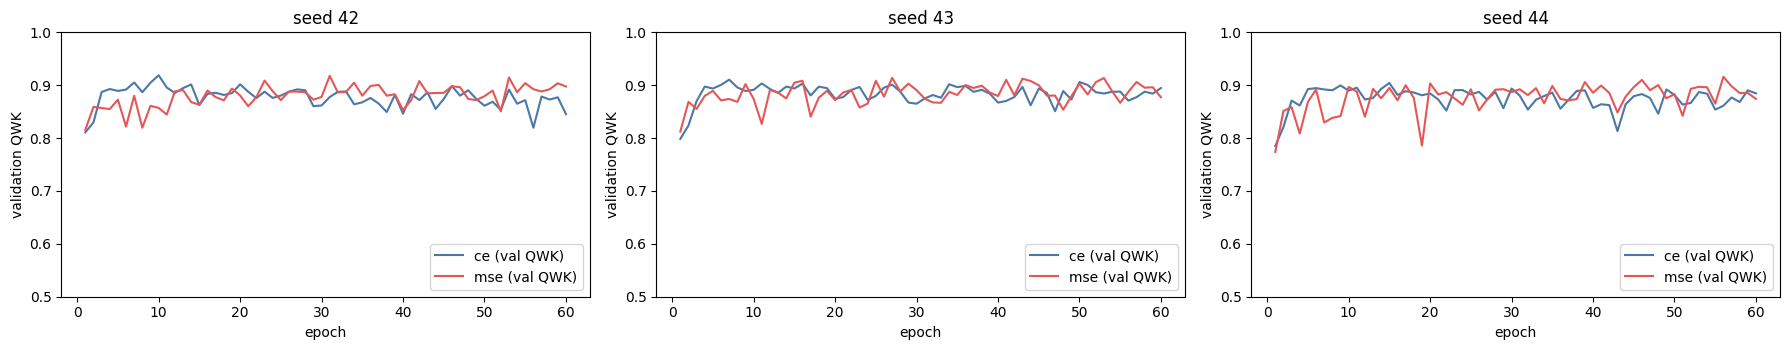

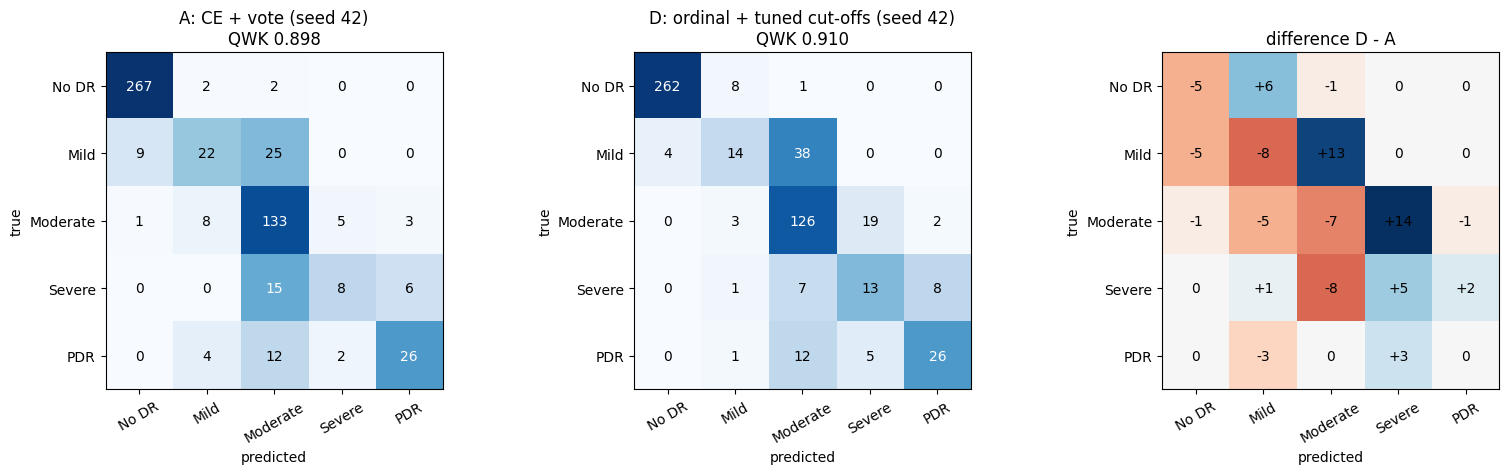

In [15]:
seeds_main = sorted({seed for dedupe, seed, _, _ in pairs() if not dedupe})
fig, axes = plt.subplots(1, len(seeds_main), figsize=(6 * len(seeds_main), 3.6), squeeze=False)
for ax, seed in zip(axes[0], seeds_main):
    for loss, color in (("ce", "#4C78A8"), ("mse", "#E45756")):
        log = runs[f"{loss}_s{seed}"]["log"]
        ax.plot(log["epoch"], log["val_qwk"], color=color, label=f"{loss} (val QWK)")
    ax.set(title=f"seed {seed}", xlabel="epoch", ylabel="validation QWK", ylim=(0.5, 1.0))
    ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "validation_curves.png", dpi=150); plt.show()


def plot_cm(ax, cm, title, cmap="Blues", vmax=None, diverging=False):
    shown = cm if diverging else cm / cm.sum(1, keepdims=True).clip(1)
    limit = vmax or (np.abs(cm).max() or 1)
    ax.imshow(shown, cmap=cmap, vmin=-limit if diverging else 0, vmax=limit if diverging else 1)
    for r in range(NUM_CLASSES):
        for c in range(NUM_CLASSES):
            ax.text(c, r, f"{cm[r, c]:+d}" if diverging and cm[r, c] else cm[r, c], ha="center", va="center",
                    color="white" if not diverging and shown[r, c] > 0.5 else "black")
    ax.set(xticks=range(NUM_CLASSES), yticks=range(NUM_CLASSES), xlabel="predicted", ylabel="true", title=title)
    ax.set_xticklabels(CLASS_NAMES, rotation=30); ax.set_yticklabels(CLASS_NAMES)


seed0 = seeds_main[0]
cms = {}
for arm in ("A", "D"):
    y, pred = decisions[(False, seed0, "ensemble", arm)]
    cms[arm] = confusion_matrix(y, pred, labels=list(range(NUM_CLASSES)))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
plot_cm(axes[0], cms["A"], f"A: CE + vote (seed {seed0})\nQWK {qwk(*decisions[(False, seed0, 'ensemble', 'A')]):.3f}")
plot_cm(axes[1], cms["D"], f"D: ordinal + tuned cut-offs (seed {seed0})\nQWK {qwk(*decisions[(False, seed0, 'ensemble', 'D')]):.3f}")
plot_cm(axes[2], cms["D"] - cms["A"], "difference D - A", cmap="RdBu", diverging=True)
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_A_vs_D.png", dpi=150); plt.show()

## 11. Failure analysis (M5)

Three questions about the errors of the hypothesis arm (D, first seed, ensemble):

1. **Label noise:** are errors more common on images whose byte-identical copies carry conflicting grades?
2. **Image quality:** are errors concentrated in blurry or dark photos? Sharpness = variance of the Laplacian; brightness = mean grey level inside the retina.
3. **What does the model look at?** Grad-CAM heat maps for missed Severe cases, the largest errors and correctly found Severe/PDR cases.

Test images in a conflicting-duplicate group: 7 of 550
  A: error rate 86% on conflicting duplicates vs 16% on the rest
  D: error rate 86% on conflicting duplicates vs 19% on the rest


,images,median sharpness,median brightness
correct,441,62.8,92.9
off by 1,92,52.1,87.8
off by >= 2,17,48.1,88.4


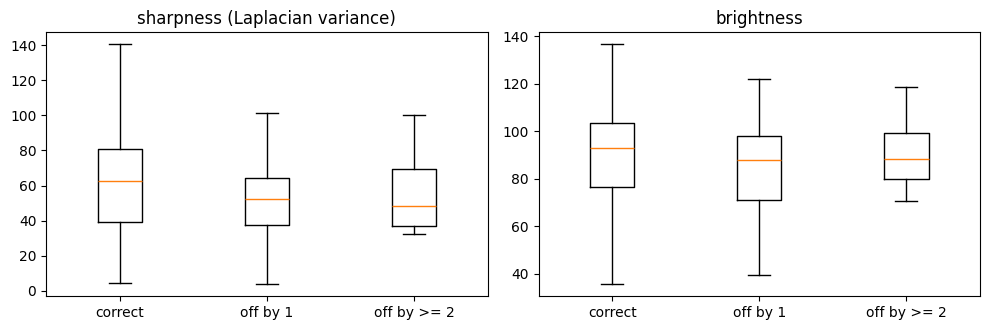

In [16]:
y_test, pred_a = decisions[(False, seed0, "ensemble", "A")]
_, pred_d = decisions[(False, seed0, "ensemble", "D")]
test_idx = SPLITS[False]["test"]

conflict = df["conflicting_duplicate"].to_numpy()[test_idx]
print(f"Test images in a conflicting-duplicate group: {conflict.sum()} of {len(conflict)}")
for arm, pred in (("A", pred_a), ("D", pred_d)):
    wrong = pred != y_test
    rate_conflict = wrong[conflict].mean() if conflict.any() else float("nan")
    print(f"  {arm}: error rate {rate_conflict:.0%} on conflicting duplicates vs {wrong[~conflict].mean():.0%} on the rest")


def quality(path):
    gray = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2GRAY)
    retina = gray > 10
    return cv2.Laplacian(gray, cv2.CV_64F).var(), float(gray[retina].mean()) if retina.any() else 0.0


with ThreadPoolExecutor(os.cpu_count()) as pool:
    sharpness, brightness = map(np.array, zip(*pool.map(quality, df["path"].to_numpy()[test_idx])))
error_size = np.minimum(np.abs(pred_d - y_test), 2)
groups_q = {0: "correct", 1: "off by 1", 2: "off by >= 2"}
quality_table = pd.DataFrame({
    "images": [int((error_size == g).sum()) for g in groups_q],
    "median sharpness": [np.median(sharpness[error_size == g]) if (error_size == g).any() else np.nan for g in groups_q],
    "median brightness": [np.median(brightness[error_size == g]) if (error_size == g).any() else np.nan for g in groups_q],
}, index=list(groups_q.values()))
quality_table.to_csv(STAGE4_DIR / "error_vs_image_quality.csv")
display(quality_table.round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, values, title in ((axes[0], sharpness, "sharpness (Laplacian variance)"), (axes[1], brightness, "brightness")):
    ax.boxplot([values[error_size == g] for g in groups_q], showfliers=False)
    ax.set_xticks(range(1, len(groups_q) + 1), list(groups_q.values()))
    ax.set_title(title)
plt.tight_layout(); plt.savefig(FIG_DIR / "error_vs_image_quality.png", dpi=150); plt.show()

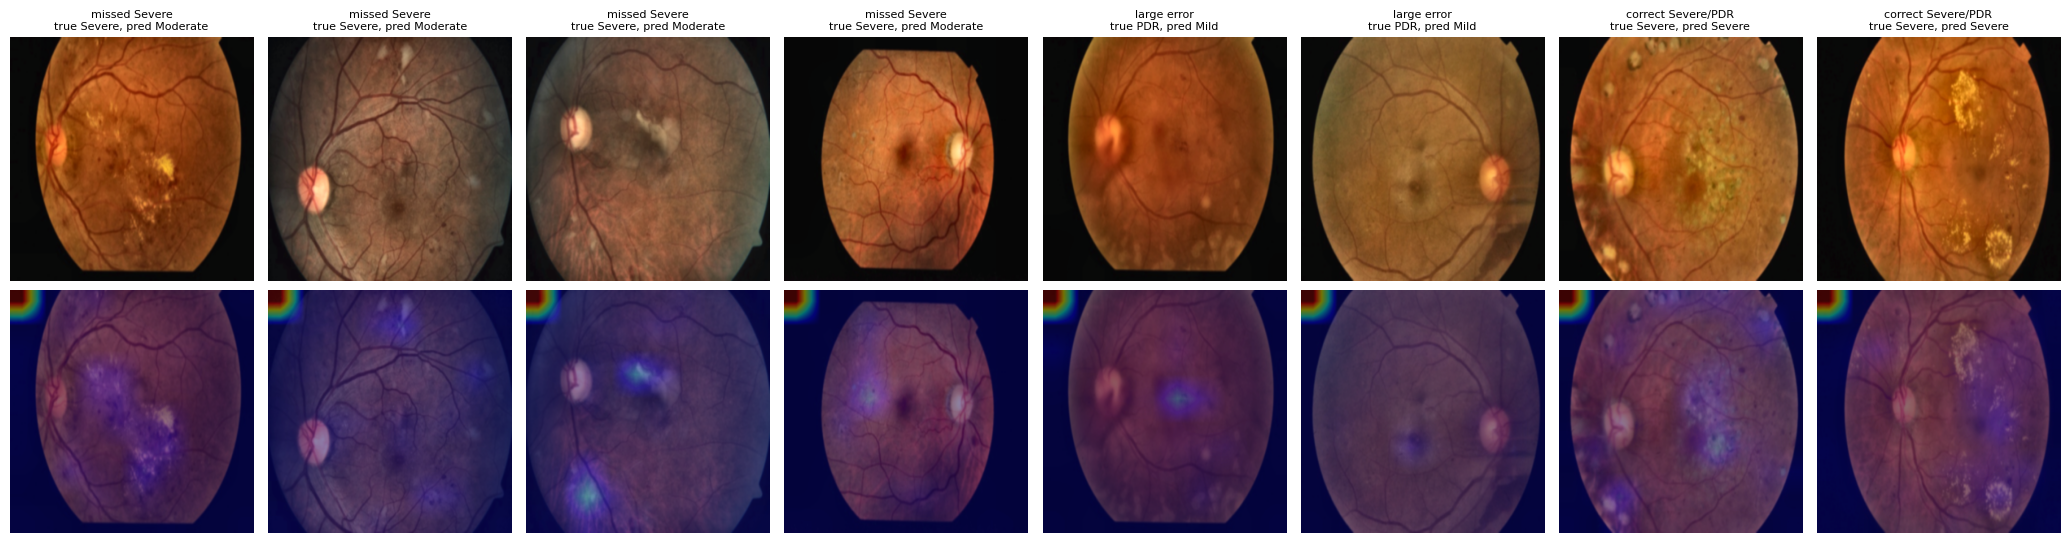

In [17]:
def grad_cam(model, image_uint8):
    # Grad-CAM on the last feature map. Target: the regression output (mse) or the predicted class's logit (ce).
    model.eval()
    feats = model.backbone.forward_features(to_model_input(image_uint8[None]))
    feats.retain_grad()
    out = model.head(model.backbone.forward_head(feats))
    target = out[0, 0] if out.shape[1] == 1 else out[0, out[0].argmax()]
    model.zero_grad()
    target.backward()
    cam = F.relu((feats.grad.mean((2, 3), keepdim=True) * feats).sum(1))[0].detach().float().cpu().numpy()
    cam = cv2.resize(cam / (cam.max() + 1e-8), image_uint8.shape[1::-1])
    return cam


# Grad-CAM explains one network, so it uses the best-validation weights of the ordinal model (arm D, single).
mse_run = runs[f"mse_s{seed0}"]
cam_model = DRNet(mse_run["config"].backbone, False, 1).to(device).to(memory_format=torch.channels_last)
cam_model.load_state_dict(torch.load(RUNS_DIR / f"mse_s{seed0}" / "best_val_weights.pt", map_location=device))
_, pred_single = decisions[(False, seed0, "single", "D")]

picks = ([("missed Severe", i) for i in np.flatnonzero((y_test == 3) & (pred_single < 3))[:4]]
         + [("large error", i) for i in np.argsort(-np.abs(pred_single - y_test))[:2] if pred_single[i] != y_test[i]]
         + [("correct Severe/PDR", i) for i in np.flatnonzero((y_test >= 3) & (pred_single == y_test))[:2]])
if picks:
    fig, axes = plt.subplots(2, len(picks), figsize=(2.6 * len(picks), 5.6), squeeze=False)
    for col, (kind, i) in enumerate(picks):
        img = images[test_idx[i]]
        cam = grad_cam(cam_model, img)
        axes[0, col].imshow(img)
        axes[0, col].set_title(f"{kind}\ntrue {CLASS_NAMES[y_test[i]]}, pred {CLASS_NAMES[pred_single[i]]}", fontsize=8)
        axes[1, col].imshow(img); axes[1, col].imshow(cam, cmap="jet", alpha=0.45)
        for ax in axes[:, col]:
            ax.axis("off")
    plt.tight_layout(); plt.savefig(FIG_DIR / "gradcam_examples.png", dpi=150); plt.show()

## 12. Post-hoc checks (added after seeing the results; not pre-registered)

Everything in this section was added **after** sections 8-11 had run, so it is exploratory and does not change the verdicts of section 9. No model is retrained: it reuses the saved outputs and weights.

1. **Votes vs. averages.** In the ensemble, arm A uses the paper's majority vote, while B, C and D average the 10 snapshots. Without any ensemble (the *single* rows) D - A is close to zero, so part of the ensemble gain may come from averaging rather than from the loss. `A_soft` is the cross-entropy ensemble with averaged probabilities and arg-max: **D - A_soft compares the two losses with the same kind of ensemble.**
2. **One interval for the mean over seeds.** The three seeds share the same 550 test images, so we resample those images and average ΔQWK over the seeds inside each resample. This gives one 95% interval for the mean effect (test-set noise only; three seeds are too few to model training noise).
3. **Image quality.** Mann-Whitney U tests of whether misgraded images are blurrier or darker than correctly graded ones.
4. **Grad-CAM inside the retina.** In the first Grad-CAM figure the peak sits in the top-left corner for every image, right or wrong. That cell of EfficientNet-B3's 10 x 10 feature map is 30-45x stronger than the median cell even for a uniform grey image (checked with the ImageNet weights): at 300 px the stride-2 convolutions pad the top and left edges but not the bottom and right ones. The corner is black background, so here feature cells that are mostly outside the retina are dropped before the map is scaled.

In [ ]:
def pooled_bootstrap(triples, n_boot=2000, seed=0):
    # triples: one (y, pred_old, pred_new) per training seed, all on the same test images.
    # Returns the 95% interval of the mean ΔQWK over seeds.
    y0 = triples[0][0]
    assert all(np.array_equal(y, y0) for y, _, _ in triples), "the seeds must share the test images"
    rng = np.random.default_rng(seed)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, len(y0), len(y0))
        diffs[i] = np.mean([qwk(y[idx], new[idx]) - qwk(y[idx], old[idx]) for y, old, new in triples])
    return np.percentile(diffs, [2.5, 97.5])


soft_rows = []
for dedupe, seed, ce_run, _ in pairs():                     # A_soft: average the snapshot probabilities, then arg-max
    probs = ce_run["snap_test"].mean(0)
    decisions[(dedupe, seed, "ensemble", "A_soft")] = (ce_run["y_test"], probs.argmax(1))
    m = compute_metrics(ce_run["y_test"], probs.argmax(1), probs)
    soft_rows.append({"data": "dedupe" if dedupe else "main", "seed": seed, "mode": "ensemble", "arm": "A_soft",
                      **{k: v for k, v in m.items() if k != "confusion_matrix"}})
soft = pd.DataFrame(soft_rows)
soft.to_csv(STAGE4_DIR / "posthoc_soft_vote.csv", index=False)

POSTHOC = [("ensemble", "D", "A"), ("ensemble", "D", "A_soft"), ("ensemble", "A_soft", "A"), ("ensemble", "B", "A"),
           ("ensemble", "C", "A"), ("ensemble", "D", "C"),
           ("single", "D", "A"), ("single", "B", "A"), ("single", "C", "A"), ("single", "D", "C")]
post_rows = []
for mode, new, old in POSTHOC:
    triples = {}
    for dedupe, seed, _, _ in pairs():
        y, pred_old = decisions[(dedupe, seed, mode, old)]
        triples[(dedupe, seed)] = (y, pred_old, decisions[(dedupe, seed, mode, new)][1])
    groups = [(("dedupe" if dedupe else "main"), str(seed), [t]) for (dedupe, seed), t in triples.items()
              if "A_soft" in (new, old)]                    # the other per-seed rows are already in paired_bootstrap.csv
    main_triples = [t for (dedupe, _), t in triples.items() if not dedupe]
    groups.append(("main", f"mean of {len(main_triples)}", main_triples))
    for data, seed, ts in groups:
        lo, hi = pooled_bootstrap(ts)
        delta = np.mean([qwk(y, new_) - qwk(y, old_) for y, old_, new_ in ts])
        post_rows.append({"data": data, "seed": seed, "mode": mode, "contrast": f"{new} - {old}",
                          "delta_qwk": delta, "ci_low": lo, "ci_high": hi, "excludes_0": bool(lo > 0 or hi < 0)})
posthoc = pd.DataFrame(post_rows)
posthoc.to_csv(STAGE4_DIR / "posthoc_bootstrap.csv", index=False)

COMPARE = ["qwk", "macro_f1", "recall_Severe", "recall_PDR", "off_by_2_or_more", "ref_sensitivity", "ref_specificity"]
ens_main = pd.concat([main[main["mode"] == "ensemble"], soft[soft["data"] == "main"]])
print("Ensemble, main split, mean over seeds:")
display(ens_main.groupby("arm")[COMPARE].mean().loc[["A", "A_soft", "B", "C", "D"]].round(3))
display(posthoc.style.format(precision=3).hide(axis="index"))

In [ ]:
from scipy.stats import mannwhitneyu

wrong = error_size > 0                                      # arm D, first seed, ensemble (as in section 11)
quality_rows = []
for name, values in (("sharpness", sharpness), ("brightness", brightness)):
    p = float(mannwhitneyu(values[wrong], values[~wrong]).pvalue)
    quality_rows.append({"measure": name, "median correct": np.median(values[~wrong]),
                         "median misgraded": np.median(values[wrong]), "n correct": int((~wrong).sum()),
                         "n misgraded": int(wrong.sum()), "mann_whitney_p": p})
quality_test = pd.DataFrame(quality_rows)
quality_test.to_csv(STAGE4_DIR / "posthoc_image_quality.csv", index=False)
quality_test.round(3)

In [ ]:
def grad_cam_retina(model, image_uint8):
    # Same Grad-CAM as section 11, but feature cells that are mostly outside the retina are dropped before
    # scaling, so the top-left padding cell cannot dominate. Also returns that cell's share of the raw map.
    model.eval()
    feats = model.backbone.forward_features(to_model_input(image_uint8[None]))
    feats.retain_grad()
    out = model.head(model.backbone.forward_head(feats))
    target = out[0, 0] if out.shape[1] == 1 else out[0, out[0].argmax()]
    model.zero_grad()
    target.backward()
    cam = F.relu((feats.grad.mean((2, 3), keepdim=True) * feats).sum(1))[0].detach().float().cpu().numpy()
    corner_share = float(cam[0, 0] / (cam.sum() + 1e-8))
    retina = (cv2.cvtColor(image_uint8, cv2.COLOR_RGB2GRAY) > 10).astype(np.float32)
    inside = cv2.resize(retina, cam.shape[::-1], interpolation=cv2.INTER_AREA) >= 0.5
    cam = np.where(inside, cam, 0.0)
    cam = cv2.resize(cam / (cam.max() + 1e-8), image_uint8.shape[1::-1]) * retina
    return cam, corner_share


if picks:
    fig, axes = plt.subplots(3, len(picks), figsize=(2.6 * len(picks), 8.4), squeeze=False)
    for col, (kind, i) in enumerate(picks):
        img = images[test_idx[i]]
        cam_raw = grad_cam(cam_model, img)
        cam_in, corner_share = grad_cam_retina(cam_model, img)
        axes[0, col].imshow(img)
        axes[0, col].set_title(f"{kind}\ntrue {CLASS_NAMES[y_test[i]]}, pred {CLASS_NAMES[pred_single[i]]}", fontsize=8)
        axes[1, col].imshow(img); axes[1, col].imshow(cam_raw, cmap="jet", alpha=0.45)
        axes[1, col].set_title(f"whole image (top-left cell {corner_share:.0%})", fontsize=8)
        axes[2, col].imshow(img); axes[2, col].imshow(cam_in, cmap="jet", alpha=0.45)
        axes[2, col].set_title("retina only", fontsize=8)
        for ax in axes[:, col]:
            ax.axis("off")
    plt.tight_layout(); plt.savefig(FIG_DIR / "gradcam_retina.png", dpi=150); plt.show()

## 13. Writing it up (M5)

**Which numbers go in the paper**

* **Main table:** the mean ± std table of section 8 (ensemble rows A-D, plus single rows), with the paper's 0.954 and the Stage 3 results for context.
* **Is the change real?** The `D - A` rows of the paired bootstrap, per seed.
* **Prediction check:** the table of section 9, unchanged, even where a prediction failed. The course grades the reasoning, not whether we guessed right.
* **Ablation:** B - A (decision rule only), C - A (loss only), D - C (cut-offs on top of the ordinal loss).
* **Failure analysis:** the confusion-matrix difference, the duplicate and image-quality results, and the Grad-CAM figure.
* **Limitations:** one dataset, one split, 3 seeds, a 550-image test set (29 Severe), cut-offs tuned on 550 validation images, and no external validation. No clinical claims.

**Files written to `MyDrive/dr-grading/stage4/`:** `results_per_seed.csv`, `results_mean_over_seeds.csv`, `paired_bootstrap.csv`, `prediction_check.csv`, `cutoffs.json`, `error_vs_image_quality.csv`, `posthoc_soft_vote.csv`, `posthoc_bootstrap.csv`, `posthoc_image_quality.csv`, `figures/{validation_curves, confusion_A_vs_D, error_vs_image_quality, gradcam_examples, gradcam_retina}.png`, and for each run `runs/<name>/{config.json, log.csv, outputs.npz, results.json, best_val_weights.pt}`. Download the folder (without the `.pt` files) and commit it to `dr-repro/results/stage4/`.